<a href="https://colab.research.google.com/github/juanchos37/control-microbiologico-python/blob/main/project12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd

# 1. Creamos el diccionario con los números de bacterias reales
datos_laboratorio = {
    'lote': ['L-01', 'L-02', 'L-03', 'L-04', 'L-05', 'L-06'],
    'producto': ['Queso Fresco', 'Leche Entera', 'Queso Fresco', 'Jamón Cárnico', 'Leche Entera', 'Yogurt'],
    'microorganismo': ['E. coli', 'Mesófilos', 'Salmonella', 'Listeria', 'Mesófilos', 'Mohos'],
    'conteo_ufc': [450, 12000, 0, 0, 85000, 40],
    'limite_legal': [100, 50000, 0, 0, 50000, 100]
}

# 2. Convertimos el diccionario en una tabla de Pandas (DataFrame)
df = pd.DataFrame(datos_laboratorio)

# 3. Visualizamos la tabla en pantalla
df


,lote,producto,microorganismo,conteo_ufc,limite_legal
0,L-01,Queso Fresco,E. coli,450,100
1,L-02,Leche Entera,Mesófilos,12000,50000
2,L-03,Queso Fresco,Salmonella,0,0
3,L-04,Jamón Cárnico,Listeria,0,0
4,L-05,Leche Entera,Mesófilos,85000,50000
5,L-06,Yogurt,Mohos,40,100


In [5]:
df['resultado'] = df.apply(lambda fila: 'Fuera de Norma' if fila['conteo_ufc'] > fila['limite_legal'] else 'Cumple', axis=1)
df


,lote,producto,microorganismo,conteo_ufc,limite_legal,resultado
0,L-01,Queso Fresco,E. coli,450,100,Fuera de Norma
1,L-02,Leche Entera,Mesófilos,12000,50000,Cumple
2,L-03,Queso Fresco,Salmonella,0,0,Cumple
3,L-04,Jamón Cárnico,Listeria,0,0,Cumple
4,L-05,Leche Entera,Mesófilos,85000,50000,Fuera de Norma
5,L-06,Yogurt,Mohos,40,100,Cumple


In [6]:
# 1. Primero asegurémonos de crear la columna de resultado (por si no la habías corrido)
df['resultado'] = df.apply(lambda fila: 'Fuera de Norma' if fila['conteo_ufc'] > fila['limite_legal'] else 'Cumple', axis=1)

# 2. RESOLVEMOS EL RETO: Filtramos la tabla para ver solo los rechazados
lotes_rechazados = df[df['resultado'] == 'Fuera de Norma']

# 3. Mostramos la nueva tabla filtrada
lotes_rechazados


,lote,producto,microorganismo,conteo_ufc,limite_legal,resultado
0,L-01,Queso Fresco,E. coli,450,100,Fuera de Norma
4,L-05,Leche Entera,Mesófilos,85000,50000,Fuera de Norma


In [7]:
# Contar cuántos análisis se hicieron por cada tipo de producto
df.groupby('producto').size()


,0
producto,
Jamón Cárnico,1
Leche Entera,2
Queso Fresco,2
Yogurt,1


In [8]:
# Así exportas cualquier tabla de Pandas a un archivo Excel real
df.to_excel('mis_primeros_resultados_micro.xlsx', index=False)


/tmp/ipykernel_819/4197195859.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='lote', y='conteo_ufc', data=df, palette='viridis')


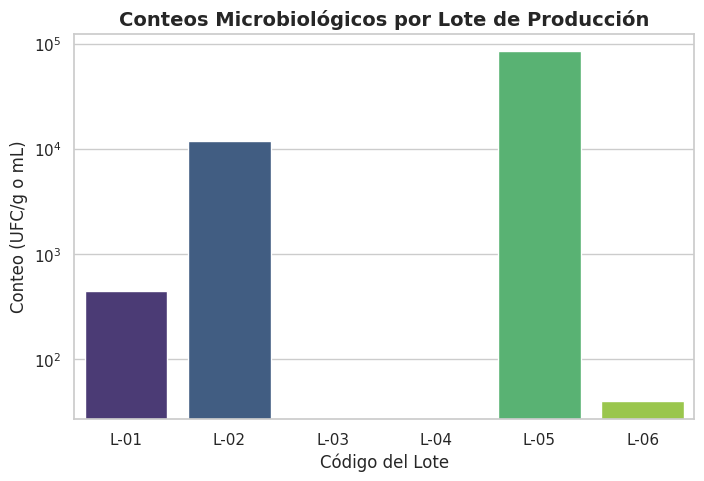

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configuramos el estilo visual del gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5)) # Tamaño del gráfico (Ancho, Alto)

# 2. Creamos el gráfico de barras
# Elegimos qué va en el eje X, en el eje Y y de dónde salen los datos (df)
sns.barplot(x='lote', y='conteo_ufc', data=df, palette='viridis')

# 3. Personalizamos los textos del gráfico
plt.title('Conteos Microbiológicos por Lote de Producción', fontsize=14, fontweight='bold')
plt.xlabel('Código del Lote', fontsize=12)
plt.ylabel('Conteo (UFC/g o mL)', fontsize=12)

# 4. Mostramos el gráfico en pantalla
plt.yscale('log')

plt.show()


In [11]:
# Ordenamos la tabla por la columna 'conteo_ufc' de mayor a menor (ascending=False)
df_ordenado = df.sort_values(by='conteo_ufc', ascending=False)

# Mostramos la tabla ordenada
df_ordenado


,lote,producto,microorganismo,conteo_ufc,limite_legal,resultado
4,L-05,Leche Entera,Mesófilos,85000,50000,Fuera de Norma
1,L-02,Leche Entera,Mesófilos,12000,50000,Cumple
0,L-01,Queso Fresco,E. coli,450,100,Fuera de Norma
5,L-06,Yogurt,Mohos,40,100,Cumple
3,L-04,Jamón Cárnico,Listeria,0,0,Cumple
2,L-03,Queso Fresco,Salmonella,0,0,Cumple


In [12]:
# 1. Filtramos solo los que no cumplen y ordénalos del más contaminado al menos contaminado
reporte_critico = df[df['resultado'] == 'Fuera de Norma'].sort_values(by='conteo_ufc', ascending=False)

print("🚨 REPORTE DE ACCIÓN INMEDIATA - LOTES RECHAZADOS 🚨")
print("====================================================")
reporte_critico


🚨 REPORTE DE ACCIÓN INMEDIATA - LOTES RECHAZADOS 🚨


,lote,producto,microorganismo,conteo_ufc,limite_legal,resultado
4,L-05,Leche Entera,Mesófilos,85000,50000,Fuera de Norma
0,L-01,Queso Fresco,E. coli,450,100,Fuera de Norma


In [15]:
import sqlite3
import pandas as pd

# 1. Creamos y nos conectamos a una base de datos en la memoria de Colab
conexion = sqlite3.connect('laboratorio.db')

# 2. Creamos una tabla llamada 'microbiologia' usando lenguaje SQL puro
cursor = conexion.cursor()
cursor.execute('''
    CREATE TABLE IF NOT EXISTS resultados (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        lote TEXT,
        producto TEXT,
        microorganismo TEXT,
        conteo_ufc INTEGER,
        limite_legal INTEGER
    )
''')

# 3. Metemos los datos de tus análisis dentro de la base de datos
datos = [
    ('L-01', 'Queso Fresco', 'E. coli', 1200, 100),
    ('L-02', 'Leche Entera', 'Mesófilos', 4500, 50000),
    ('L-03', 'Queso Fresco', 'Salmonella', 0, 0),
    ('L-04', 'Jamón Cárnico', 'Listeria', 0, 0),
    ('L-05', 'Leche Entera', 'Mesófilos', 48000, 30000)
]

cursor.executemany('INSERT INTO resultados (lote, producto, microorganismo, conteo_ufc, limite_legal) VALUES (?, ?, ?, ?, ?)', datos)
conexion.commit()

# 4. LA PRÁCTICA REAL: Hacemos una consulta SQL para traer los datos a Pandas
# Aquí le pedimos a la base de datos solo los lotes donde se superó el límite legal
consulta_sql = "SELECT lote, producto, microorganismo, conteo_ufc FROM resultados WHERE conteo_ufc > limite_legal;"

# Pandas se conecta, ejecuta el SQL y nos crea la tabla
df_desde_sql = pd.read_sql_query(consulta_sql, conexion)

# 5. Cerramos la conexión
conexion.close()

# Mostramos el resultado en pantalla
print("--- DATOS EXTRAÍDOS DE LA BASE DE DATOS MEDIANTE SQL ---")
df_desde_sql


--- DATOS EXTRAÍDOS DE LA BASE DE DATOS MEDIANTE SQL ---


,lote,producto,microorganismo,conteo_ufc
0,L-01,Queso Fresco,E. coli,1200
1,L-05,Leche Entera,Mesófilos,48000
2,L-01,Queso Fresco,E. coli,1200
3,L-05,Leche Entera,Mesófilos,48000


In [16]:
import pandas as pd
import numpy as np

# 1. Creamos una tabla "sucia" con errores comunes de planta
datos_sucios = {
    'fecha': ['2026-10-25', '2026-10-25', '2026-10-26', '2026-10-26', '2026-10-27', '2026-10-27'],
    'operario': ['Carlos', 'Carlos', 'Ana', 'Ana', None, 'Luis'], # ¡Hay un dato vacío (None)!
    'temperatura_c': [3.5, 3.5, np.nan, 4.2, 3.9, 12.0],        # np.nan es un dato faltante. Fila 1 repetida. Lote 6 muy alto.
    'cuarto_frio': ['CUARTO-01', 'CUARTO-01', 'CUARTO-01', 'cuarto-01', 'CUARTO-01', 'CUARTO-01'] # "cuarto-01" en minúscula
}

df_sucio = pd.DataFrame(datos_sucios)
print("--- ❌ TABLA SUCIA ORIGINAL ---")
print(df_sucio)
print("\n" + "="*40 + "\n")

# ==========================================
# PASOS DE DESINFECCIÓN DE DATOS CON PANDAS
# ==========================================

# Paso 1: Eliminar filas duplicadas exactamente iguales
# (Carlos registró el mismo dato dos veces el 25 de octubre)
df_limpio = df_sucio.drop_duplicates()

# Paso 2: Homogeneizar el texto (Pasar todo a MAYÚSCULAS)
# Evita que Python piense que 'CUARTO-01' y 'cuarto-01' son lugares diferentes
df_limpio['cuarto_frio'] = df_limpio['cuarto_frio'].str.upper()

# Paso 3: Llenar datos faltantes (Imputación)
# Si no sabemos qué operario midió, le ponemos "No Registrado" en lugar de None
df_limpio['operario'] = df_limpio['operario'].fillna('No Registrado')

# Si falta una temperatura, le ponemos el promedio de las demás para no alterar la estadística
promedio_temp = df_limpio['temperatura_c'].mean()
df_limpio['temperatura_c'] = df_limpio['temperatura_c'].fillna(promedio_temp)

print("---  TABLA TOTALMENTE LIMPIA Y CORREGIDA ---")
df_limpio


--- ❌ TABLA SUCIA ORIGINAL ---
        fecha operario  temperatura_c cuarto_frio
0  2026-10-25   Carlos            3.5   CUARTO-01
1  2026-10-25   Carlos            3.5   CUARTO-01
2  2026-10-26      Ana            NaN   CUARTO-01
3  2026-10-26      Ana            4.2   cuarto-01
4  2026-10-27     None            3.9   CUARTO-01
5  2026-10-27     Luis           12.0   CUARTO-01


---  TABLA TOTALMENTE LIMPIA Y CORREGIDA ---


/tmp/ipykernel_819/449970715.py:27: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_limpio['cuarto_frio'] = df_limpio['cuarto_frio'].str.upper()
/tmp/ipykernel_819/449970715.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_limpio['operario'] = df_limpio['operario'].fillna('No Registrado')
/tmp/ipykernel_819/449970715.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the docume

,fecha,operario,temperatura_c,cuarto_frio
0,2026-10-25,Carlos,3.5,CUARTO-01
2,2026-10-26,Ana,5.9,CUARTO-01
3,2026-10-26,Ana,4.2,CUARTO-01
4,2026-10-27,No Registrado,3.9,CUARTO-01
5,2026-10-27,Luis,12.0,CUARTO-01


In [17]:
import pandas as pd
import numpy as np

# 1. Creamos una tabla simulada de laboratorio con datos faltantes (None / np.nan)
datos_analisis = {
    'lote': ['L-10', 'L-11', 'L-12', 'L-13', 'L-14'],
    'producto': ['Jamón Cárnico', 'Jamón Cárnico', 'Queso Análogo', 'Queso Análogo', 'Yogurt Fresa'],
    'operario': ['Ana', None, 'Carlos', 'Carlos', 'Ana'],                    # El lote L-11 no tiene operario
    'conteo_ufc': [150, 240, np.nan, 310, 0]                                # El lote L-12 no se pudo contar
}

df_laboratorio = pd.DataFrame(datos_analisis)
print("--- ❌ TABLA ANTES DE ELIMINAR FILAS INCOMPLETAS ---")
print(df_laboratorio)
print("\n" + "="*50 + "\n")

# =======================================================
# ESTRATEGIAS PARA ELIMINAR FILAS CON .dropna()
# =======================================================

# Estrategia A: Eliminar CUALQUIER fila donde falte al menos un dato
df_descarte_total = df_laboratorio.dropna()

print("--- 🗑️ ESTRATEGIA A: SE ELIMINÓ CUALQUIER FILA CON NULOS ---")
print(df_descarte_total)
print("\n" + "="*50 + "\n")

# Estrategia B: Eliminar filas solo si falta el dato en una columna crítica
# (Por ejemplo, si falta el conteo de bacterias, la fila no sirve)
df_descarte_critico = df_laboratorio.dropna(subset=['conteo_ufc'])

print("--- 🔬 ESTRATEGIA B: FILAS ELIMINADAS SOLO SI FALTA EL CONTEO_UFC ---")
df_descarte_critico


--- ❌ TABLA ANTES DE ELIMINAR FILAS INCOMPLETAS ---
   lote       producto operario  conteo_ufc
0  L-10  Jamón Cárnico      Ana       150.0
1  L-11  Jamón Cárnico     None       240.0
2  L-12  Queso Análogo   Carlos         NaN
3  L-13  Queso Análogo   Carlos       310.0
4  L-14   Yogurt Fresa      Ana         0.0


--- 🗑️ ESTRATEGIA A: SE ELIMINÓ CUALQUIER FILA CON NULOS ---
   lote       producto operario  conteo_ufc
0  L-10  Jamón Cárnico      Ana       150.0
3  L-13  Queso Análogo   Carlos       310.0
4  L-14   Yogurt Fresa      Ana         0.0


--- 🔬 ESTRATEGIA B: FILAS ELIMINADAS SOLO SI FALTA EL CONTEO_UFC ---


,lote,producto,operario,conteo_ufc
0,L-10,Jamón Cárnico,Ana,150.0
1,L-11,Jamón Cárnico,None,240.0
3,L-13,Queso Análogo,Carlos,310.0
4,L-14,Yogurt Fresa,Ana,0.0


In [18]:
df_limpio = df_laboratorio.dropna().reset_index(drop=True)


In [19]:
import pandas as pd
import numpy as np

# 1. Creamos la tabla con conteos microbiológicos típicos
datos_micro = {
    'lote': ['L-20', 'L-21', 'L-22', 'L-23', 'L-24'],
    'producto': ['Carne Molida', 'Carne Molida', 'Pollo Entero', 'Pollo Entero', 'Embutido'],
    'conteo_ufc': [5000, 120000, 450, 850000, 0] # El lote 24 dio Ausencia (0 bacterias)
}

df_log = pd.DataFrame(datos_micro)

# 2. LA MAGIA DE NUMPY: Convertir a log10 de forma segura
# Nota: El logaritmo de 0 matemáticamente no existe (-infinito).
# Los microbiólogos sumamos 1 a los conteos antes de aplicar log10 para evitar errores.
df_log['log_ufc'] = np.log10(df_log['conteo_ufc'] + 1)

# 3. Redondeamos a 2 decimales para que sea estético en los reportes
df_log['log_ufc'] = df_log['log_ufc'].round(2)

print("--- 🔬 TABLA TRANSFORMADA A ESCALA CIENTÍFICA (LOG10) ---")
df_log


--- 🔬 TABLA TRANSFORMADA A ESCALA CIENTÍFICA (LOG10) ---


,lote,producto,conteo_ufc,log_ufc
0,L-20,Carne Molida,5000,3.70
1,L-21,Carne Molida,120000,5.08
2,L-22,Pollo Entero,450,2.65
3,L-23,Pollo Entero,850000,5.93
4,L-24,Embutido,0,0.00


/tmp/ipykernel_819/1408712786.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='lote', y='conteo_ufc', data=df_log, ax=axes[0], palette='Reds_r')
/tmp/ipykernel_819/1408712786.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='lote', y='log_ufc', data=df_log, ax=axes[1], palette='Blues_r')


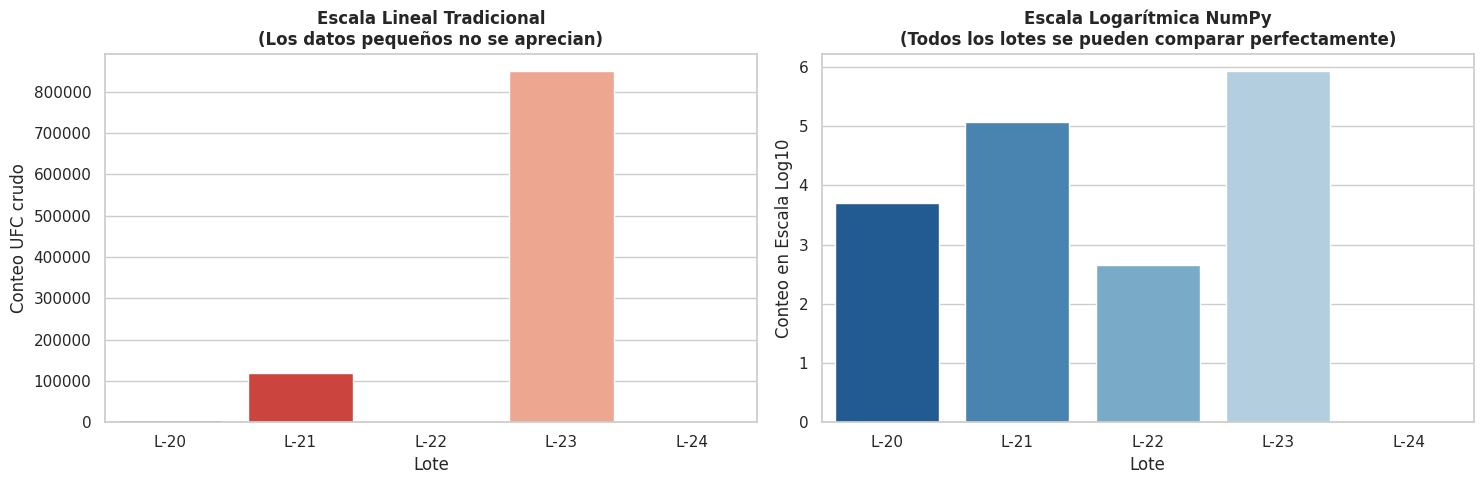

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de la pantalla para mostrar 2 gráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.set_theme(style="whitegrid")

# --- GRÁFICO 1: ESCALA LINEAL (TRADICIONAL) ---
sns.barplot(x='lote', y='conteo_ufc', data=df_log, ax=axes[0], palette='Reds_r')
axes[0].set_title('Escala Lineal Tradicional\n(Los datos pequeños no se aprecian)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Lote')
axes[0].set_ylabel('Conteo UFC crudo')

# --- GRÁFICO 2: ESCALA LOGARÍTMICA (CIENTÍFICA) ---
sns.barplot(x='lote', y='log_ufc', data=df_log, ax=axes[1], palette='Blues_r')
axes[1].set_title('Escala Logarítmica NumPy\n(Todos los lotes se pueden comparar perfectamente)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Lote')
axes[1].set_ylabel('Conteo en Escala Log10')

# Mostrar los gráficos
plt.tight_layout()
plt.show()


In [21]:
import sqlite3
import pandas as pd

# 1. Conectamos a nuestra base de datos relacional en Colab
conexion = sqlite3.connect('industria_alimentos.db')
cursor = conexion.cursor()

# 2. Crear Tabla de Proveedores
cursor.execute('''
    CREATE TABLE IF NOT EXISTS proveedores (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        nombre_empresa TEXT,
        contacto TEXT,
        ciudad TEXT
    )
''')

# 3. Crear Tabla de Muestras (Conectada a proveedores mediante una llave foránea)
cursor.execute('''
    CREATE TABLE IF NOT EXISTS muestras_micro (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        lote TEXT,
        materia_prima TEXT,
        conteo_ufc INTEGER,
        proveedor_id INTEGER,
        FOREIGN KEY (proveedor_id) REFERENCES proveedores(id)
    )
''')

# 4. Insertar datos de prueba (Solo si la tabla está vacía)
cursor.execute("SELECT COUNT(*) FROM proveedores")
if cursor.fetchone()[0] == 0:
    # Insertamos 3 proveedores
    cursor.executemany("INSERT INTO proveedores (nombre_empresa, contacto, ciudad) VALUES (?, ?, ?)", [
        ('Carnes del Norte', 'Carlos Mendoza', 'Medellín'),
        ('Lácteos el Prado', 'Ana Silva', 'Bogotá'),
        ('Distribuidora Avícola', 'Luis Gómez', 'Cali')
    ])

    # Insertamos muestras microbiológicas asignando el ID del proveedor correspondiente
    cursor.executemany("INSERT INTO muestras_micro (lote, materia_prima, conteo_ufc, proveedor_id) VALUES (?, ?, ?, ?)", [
        ('L-901', 'Carne de Res', 850000, 1), # Pertenece a Carnes del Norte (ID 1)
        ('L-902', 'Leche Cruda', 1200, 2),    # Pertenece a Lácteos el Prado (ID 2)
        ('L-903', 'Pechuga Pollo', 4500, 3),   # Pertenece a Distribuidora Avícola (ID 3)
        ('L-904', 'Carne de Res', 920000, 1)  # Otra muestra de Carnes del Norte (ID 1)
    ])
    conexion.commit()

print("¡Tablas relacionales creadas e indexadas correctamente!")
conexion.close()


¡Tablas relacionales creadas e indexadas correctamente!


In [22]:
conexion = sqlite3.connect('industria_alimentos.db')

# Escribimos la consulta SQL que cruza ambas tablas usando el punto de unión: proveedor_id
consulta_join = '''
SELECT
    m.lote,
    m.materia_prima,
    m.conteo_ufc,
    p.nombre_empresa,
    p.contacto
FROM muestras_micro m
INNER JOIN proveedores p ON m.proveedor_id = p.id
WHERE m.conteo_ufc > 500000;
'''

# Cargamos el resultado directamente en Pandas
df_auditoria = pd.read_sql_query(consulta_join, conexion)
conexion.close()

print("🚨 ALERTAS DE CALIDAD: MATERIA PRIMA FUERA DE NORMA CON DATOS DE PROVEEDOR 🚨")
df_auditoria


🚨 ALERTAS DE CALIDAD: MATERIA PRIMA FUERA DE NORMA CON DATOS DE PROVEEDOR 🚨


,lote,materia_prima,conteo_ufc,nombre_empresa,contacto
0,L-901,Carne de Res,850000,Carnes del Norte,Carlos Mendoza
1,L-904,Carne de Res,920000,Carnes del Norte,Carlos Mendoza


In [23]:
import sqlite3
import pandas as pd

# 1. Nos conectamos a la base de datos relacional que creamos antes
conexion = sqlite3.connect('industria_alimentos.db')

# 2. Escribimos la consulta SQL con GROUP BY y funciones de agregación
consulta_proveedores = '''
SELECT
    p.nombre_empresa AS Proveedor,
    p.ciudad AS Ciudad,
    COUNT(m.id) AS Total_Despachos_Analizados,
    ROUND(AVG(m.conteo_ufc), 2) AS Promedio_UFC_Historico
FROM proveedores p
INNER JOIN muestras_micro m ON p.id = m.proveedor_id
GROUP BY p.nombre_empresa;
'''

# 3. Cargamos los resultados estadísticos directo en Pandas
df_estadistica_proveedores = pd.read_sql_query(consulta_proveedores, conexion)
conexion.close()

print("📊 INFORME EJECUTIVO: DESEMPEÑO MICROBIOLÓGICO POR PROVEEDOR 📊")
print("=================================================================")
df_estadistica_proveedores


📊 INFORME EJECUTIVO: DESEMPEÑO MICROBIOLÓGICO POR PROVEEDOR 📊


,Proveedor,Ciudad,Total_Despachos_Analizados,Promedio_UFC_Historico
0,Carnes del Norte,Medellín,2,885000.0
1,Distribuidora Avícola,Cali,1,4500.0
2,Lácteos el Prado,Bogotá,1,1200.0


In [24]:
import sqlite3
import pandas as pd

# 1. Nos conectamos a la base de datos
conexion = sqlite3.connect('industria_alimentos.db')
cursor = conexion.cursor()

# 2. CREAMOS LA VISTA EN SQL
# Le decimos: "Guarda esta consulta bajo el nombre 'vista_desempenio_proveedores'"
cursor.execute('''
    CREATE VIEW IF NOT EXISTS vista_desempenio_proveedores AS
    SELECT
        p.nombre_empresa AS Proveedor,
        p.ciudad AS Ciudad,
        COUNT(m.id) AS Total_Despachos,
        ROUND(AVG(m.conteo_ufc), 2) AS Promedio_UFC
    FROM proveedores p
    INNER JOIN muestras_micro m ON p.id = m.proveedor_id
    GROUP BY p.nombre_empresa;
''')
conexion.commit()
print("¡Vista 'vista_desempenio_proveedores' creada con éxito en la Base de Datos!")

print("\n" + "="*60 + "\n")

# 3. LA VENTAJA: Ahora puedes consultar ese reporte complejo de forma súper simple
# Ya no escribes el JOIN, solo llamas a la vista como si fuera una tabla normal
consulta_simple = "SELECT * FROM vista_desempenio_proveedores WHERE Promedio_UFC > 10000;"

df_reporte_rapido = pd.read_sql_query(consulta_simple, conexion)
conexion.close()

print("📋 REPORTE RÁPIDO GENERADO DESDE LA VISTA (Filtrado por alto riesgo) 📋")
df_reporte_rapido


¡Vista 'vista_desempenio_proveedores' creada con éxito en la Base de Datos!


📋 REPORTE RÁPIDO GENERADO DESDE LA VISTA (Filtrado por alto riesgo) 📋


,Proveedor,Ciudad,Total_Despachos,Promedio_UFC
0,Carnes del Norte,Medellín,2,885000.0


/tmp/ipykernel_819/77697822.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  grafico = sns.barplot(


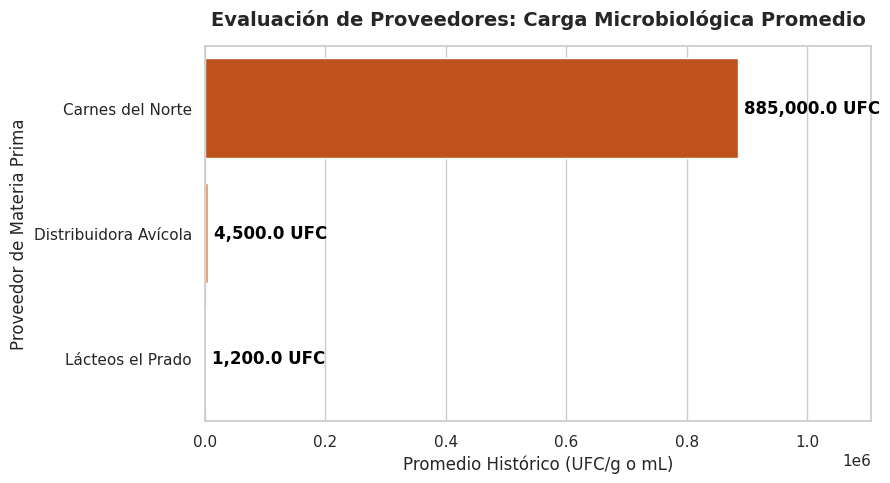

In [25]:
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Extraemos los datos desde la vista que guardamos en la base de datos
conexion = sqlite3.connect('industria_alimentos.db')
df_grafico = pd.read_sql_query("SELECT * FROM vista_desempenio_proveedores;", conexion)
conexion.close()

# 2. Configuramos el lienzo del gráfico
plt.figure(figsize=(9, 5))
sns.set_theme(style="whitegrid")

# 3. Creamos un gráfico de barras horizontales (ideal para comparar nombres de empresas)
# Usamos el promedio de UFC para el largo de la barra y el nombre del Proveedor en el eje Y
grafico = sns.barplot(
    x='Promedio_UFC',
    y='Proveedor',
    data=df_grafico,
    palette='Oranges_r' # Paleta de colores cálidos de alerta
)

# 4. Añadimos etiquetas de texto al final de cada barra con el valor exacto
for index, row in df_grafico.iterrows():
    grafico.text(
        row['Promedio_UFC'] + 10000, # Posición X un poco corrida a la derecha
        index,                       # Posición Y
        f"{row['Promedio_UFC']:,} UFC", # Texto formateado con comas
        color='black',
        ha="left",
        va="center",
        fontweight='bold'
    )

# 5. Personalizamos el diseño y los títulos
plt.title('Evaluación de Proveedores: Carga Microbiológica Promedio', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Promedio Histórico (UFC/g o mL)', fontsize=12)
plt.ylabel('Proveedor de Materia Prima', fontsize=12)

# Ajustamos los límites del eje X para que los textos no se corten
plt.xlim(0, df_grafico['Promedio_UFC'].max() * 1.25)

# 6. Mostramos la gráfica en pantalla
plt.tight_layout()
plt.show()


/tmp/ipykernel_819/780331064.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Promedio_UFC', y='Proveedor', data=df_proveedores, palette=colores)


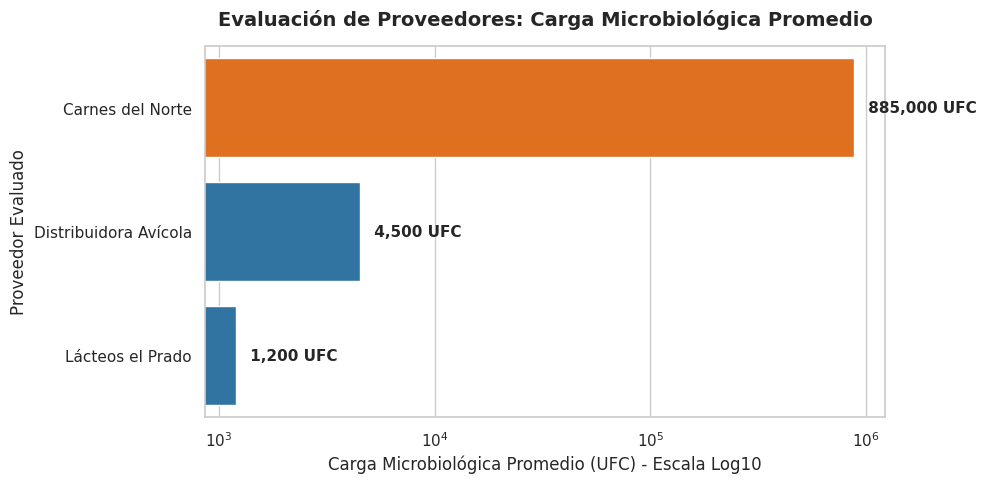

In [26]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Conectamos a la base de datos y extraemos los datos directamente de la Vista SQL
conexion = sqlite3.connect('industria_alimentos.db')
df_proveedores = pd.read_sql_query("SELECT * FROM vista_desempenio_proveedores;", conexion)
conexion.close()

# 2. Configuración estética del gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

# 3. Creamos el gráfico de barras horizontal (Cambiamos X por Y para la orientación)
# Asignamos colores específicos para resaltar el riesgo crítico
colores = ['#FF6B00' if p == 'Carnes del Norte' else '#1F77B4' for p in df_proveedores['Proveedor']]
ax = sns.barplot(x='Promedio_UFC', y='Proveedor', data=df_proveedores, palette=colores)

# 4. Cambiamos el eje X a escala logarítmica para manejar la gran diferencia de valores
plt.xscale('log')

# 5. Personalización de textos y títulos del reporte ejecutivo
plt.title('Evaluación de Proveedores: Carga Microbiológica Promedio', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Carga Microbiológica Promedio (UFC) - Escala Log10', fontsize=12)
plt.ylabel('Proveedor Evaluado', fontsize=12)

# Añadimos etiquetas de texto con los valores reales al final de cada barra para mayor claridad
for i, v in enumerate(df_proveedores['Promedio_UFC']):
    ax.text(v + (v*0.1), i, f" {v:,.0f} UFC", va='center', fontweight='bold', fontsize=11)

# 6. Desplegamos el gráfico
plt.tight_layout()
plt.show()
